# CTD micronutrient gene sets

Ten micronutrients are queried against the [CTD batch query service](https://ctdbase.org/help/linking.jsp#batchqueries)
with the `cgixns` report. The query is hierarchical, so the MeSH child terms of
each micronutrient are included, for example calcitriol below vitamin D3.

- Part A - query CTD and keep the Homo sapiens records
- Part B - drop the co-treatment records and plot the gene sets
- Part C - filter by the number of references and plot again

## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../scripts")
import ctd_micronutrient_sets as cms
import ctd_set_figure as csf

RESULTS = Path("../results/ctd")
RESULTS.mkdir(exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

### The ten micronutrients

The MeSH identifiers are the ones CTD uses. Vitamin D is queried as the parent
term, so the D2 and D3 branches are both included.

In [2]:
MICRONUTRIENTS = {
    "Vitamin A": "D014801",
    "Vitamin B6": "D025101",
    "Vitamin B12": "D014805",
    "Vitamin C": "D001205",
    "Vitamin D": "D014807",
    "Vitamin E": "D014810",
    "Iron": "D007501",
    "Folic Acid": "D005492",
    "Zinc": "D015032",
    "Selenium": "D012643",
}

ORDER = list(MICRONUTRIENTS)
COLORS = {name: csf.COLORS[name] for name in ORDER}

MIN_SET_SIZE = 5
MAX_SET_SIZE = 200
START_REFERENCES = 2

pd.DataFrame({"Micronutrient": ORDER, "MeshID": [MICRONUTRIENTS[n] for n in ORDER]})

,Micronutrient,MeshID
0,Vitamin A,D014801
1,Vitamin B6,D025101
2,Vitamin B12,D014805
3,Vitamin C,D001205
4,Vitamin D,D014807
5,Vitamin E,D014810
6,Iron,D007501
7,Folic Acid,D005492
8,Zinc,D015032
9,Selenium,D012643


## Part A: query CTD, keep Homo sapiens

`fetch_all` runs one batch query per micronutrient and keeps the Homo sapiens
rows. A gene curated in several species is kept when it has a human row.

In [3]:
interactions = cms.fetch_all(MICRONUTRIENTS)
print(f"\n{len(interactions)} human interaction records, "
      f"{interactions['GeneSymbol'].nunique()} distinct genes")
interactions.head()

Vitamin A (D014801):  18333 records,  12059 human,  7936 genes


Vitamin B6 (D025101):    194 records,    122 human,    33 genes


Vitamin B12 (D014805):    236 records,     70 human,    30 genes


Vitamin C (D001205):   3566 records,   2272 human,   563 genes


Vitamin D (D014807):   7512 records,   6025 human,  3038 genes


...

Iron (D007501):   1314 records,    484 human,   214 genes


Folic Acid (D005492):  15209 records,   1715 human,  1254 genes


Zinc (D015032):   5089 records,   2452 human,  1755 genes


Selenium (D012643):   3676 records,   2071 human,  1567 genes

29728 human interaction records, 11145 distinct genes


,Micronutrient,ChemicalName,ChemicalID,CasRN,GeneSymbol,GeneID,Organism,OrganismID,Interaction,InteractionActions,PubMedIDs
0,Vitamin A,13-cis-12-(3'-carboxyphenyl)retinoic acid,C078415,141948-79-0,PLA2G2A,5320,Homo sapiens,9606,13-cis-12-(3'-carboxyphenyl)retinoic acid bind...,affects^binding|decreases^activity,7814386
1,Vitamin A,"14-hydroxy-4,14-retro-retinol",C072014,139257-77-5,PRKCA,5578,Homo sapiens,9606,"14-hydroxy-4,14-retro-retinol binds to and res...",affects^binding|increases^activity,11099483
2,Vitamin A,"3,7,11,15-tetramethyl-2,4,6,10,14-hexadecapent...",C034534,81485-25-8,CCND1,595,Homo sapiens,9606,"3,7,11,15-tetramethyl-2,4,6,10,14-hexadecapent...",decreases^expression,15475462|16596235
3,Vitamin A,"3,7,11,15-tetramethyl-2,4,6,10,14-hexadecapent...",C034534,81485-25-8,CCND1,595,Homo sapiens,9606,"3,7,11,15-tetramethyl-2,4,6,10,14-hexadecapent...",decreases^expression,15475462
4,Vitamin A,"3,7,11,15-tetramethyl-2,4,6,10,14-hexadecapent...",C034534,81485-25-8,CCND1,595,Homo sapiens,9606,(5-fluoro-2-methyl-1-(4-pyridyl)methylene-3-(N...,decreases^expression|increases^reaction,15475462


### Drop the co-treatment records

In [4]:
cotreatment = cms.is_cotreatment(interactions)
direct = interactions[~cotreatment].reset_index(drop=True)

pd.DataFrame({
    "Micronutrient": ORDER,
    "AllRecords": [int((interactions["Micronutrient"] == n).sum()) for n in ORDER],
    "CoTreatment": [int(cotreatment[interactions["Micronutrient"] == n].sum())
                    for n in ORDER],
    "Kept": [int((direct["Micronutrient"] == n).sum()) for n in ORDER],
})

,Micronutrient,AllRecords,CoTreatment,Kept
0,Vitamin A,12059,1199,10860
1,Vitamin B6,122,14,108
2,Vitamin B12,70,30,40
3,Vitamin C,2272,1692,580
4,Vitamin D,6025,1506,4519
5,Vitamin E,2458,596,1862
6,Iron,484,69,415
7,Folic Acid,1715,338,1377
8,Zinc,2452,908,1544
9,Selenium,2071,450,1621


## Part B: the gene sets before the reference filter

The records are collapsed to one row per micronutrient and gene.
`NumReferences` is the number of distinct PubMed identifiers supporting the
pair.

In [5]:
def gene_table(records):
    """Collapse the interaction records to one row per micronutrient and gene."""
    genes = records.groupby(
        ["Micronutrient", "GeneSymbol", "GeneID"], as_index=False
    ).agg(
        NumInteractions=("Interaction", "size"),
        NumReferences=("PubMedIDs",
                       lambda v: len(cms.split_references(v))),
        PubMedIDs=("PubMedIDs",
                   lambda v: "|".join(sorted(cms.split_references(v)))),
        ChemicalNames=("ChemicalName", lambda v: "|".join(sorted(set(v)))),
        InteractionActions=("InteractionActions", lambda v: "|".join(sorted(
            {a for value in v for a in str(value).split("|") if a}))),
    )
    return genes.sort_values(
        ["Micronutrient", "NumReferences", "GeneSymbol"],
        ascending=[True, False, True],
    ).reset_index(drop=True)


genes_all = gene_table(direct)
sets_all = {name: set(group["GeneSymbol"])
            for name, group in genes_all.groupby("Micronutrient")}

pd.DataFrame({
    "Micronutrient": ORDER,
    "NumGenes": [len(sets_all.get(n, ())) for n in ORDER],
    "MaxReferences": [int(genes_all.loc[genes_all["Micronutrient"] == n,
                                        "NumReferences"].max())
                      for n in ORDER],
})

,Micronutrient,NumGenes,MaxReferences
0,Vitamin A,7662,62
1,Vitamin B6,25,4
2,Vitamin B12,20,3
3,Vitamin C,259,17
4,Vitamin D,2989,86
5,Vitamin E,1517,15
6,Iron,191,13
7,Folic Acid,1005,13
8,Zinc,990,23
9,Selenium,1457,10


Written to results/ctd/ctd_micronutrients_all.png


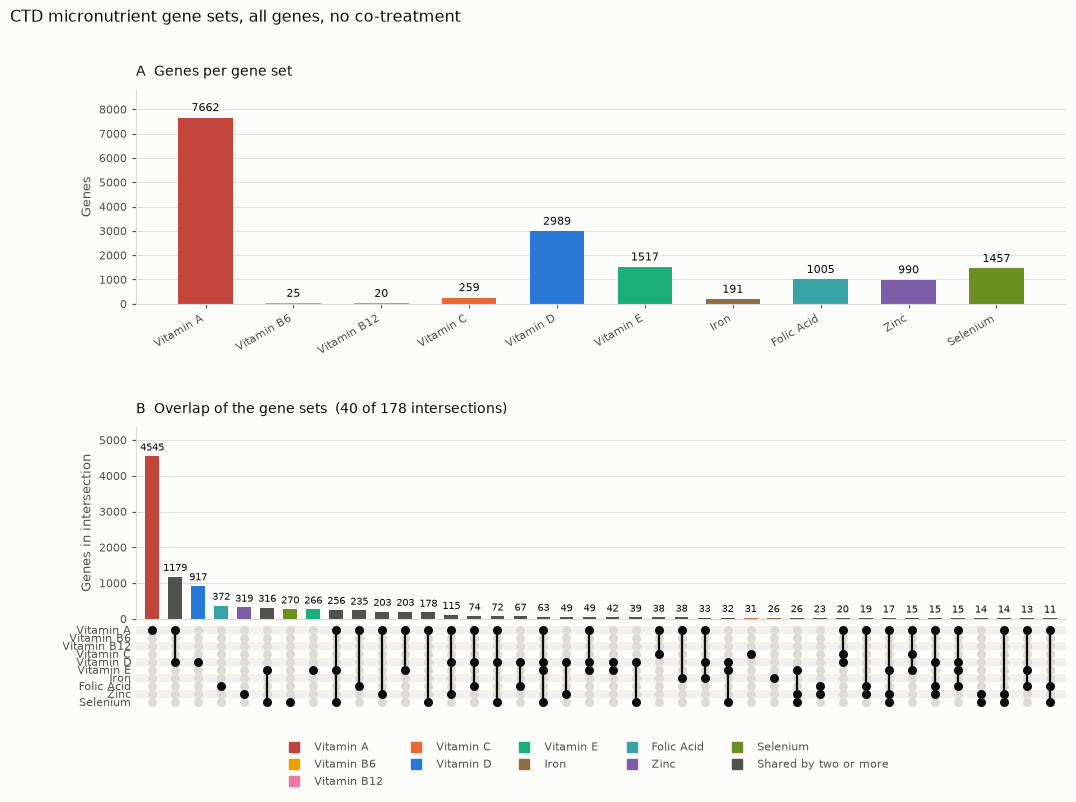

In [6]:
figure = csf.make_figure(
    sets_all,
    output_path=RESULTS / "ctd_micronutrients_all.png",
    subtitle=", all genes, no co-treatment",
    order=ORDER,
)
plt.show()

## Part C: filter by the number of references

Each set gets its own threshold, starting at 2 references. It drops to 1 below
`MIN_SET_SIZE` genes and goes up above `MAX_SET_SIZE`, bounds permitting.

In [7]:
def reference_threshold(counts, start=START_REFERENCES,
                        min_size=MIN_SET_SIZE, max_size=MAX_SET_SIZE):
    """Choose the reference threshold of one set from its reference counts."""
    counts = pd.Series(counts)
    size = lambda t: int((counts >= t).sum())

    if size(start) < min_size:
        return 1

    threshold = start
    while size(threshold) > max_size:
        if size(threshold + 1) < min_size:
            break
        threshold += 1
    return threshold


rows = []
kept = []
for name in ORDER:
    group = genes_all[genes_all["Micronutrient"] == name]
    threshold = reference_threshold(group["NumReferences"])
    filtered = group[group["NumReferences"] >= threshold].copy()
    filtered["RefThreshold"] = threshold
    kept.append(filtered)
    rows.append({
        "Micronutrient": name,
        "NumGenesBefore": len(group),
        "RefThreshold": threshold,
        "NumGenesAfter": len(filtered),
    })

genes_filtered = pd.concat(kept, ignore_index=True)
sets_filtered = {name: set(group["GeneSymbol"])
                 for name, group in genes_filtered.groupby("Micronutrient")}

pd.DataFrame(rows)

,Micronutrient,NumGenesBefore,RefThreshold,NumGenesAfter
0,Vitamin A,7662,5,158
1,Vitamin B6,25,1,25
2,Vitamin B12,20,1,20
3,Vitamin C,259,2,54
4,Vitamin D,2989,3,136
5,Vitamin E,1517,2,73
6,Iron,191,2,27
7,Folic Acid,1005,2,76
8,Zinc,990,2,120
9,Selenium,1457,2,33


In [8]:
outside = [(name, len(sets_filtered.get(name, ())))
           for name in ORDER
           if not MIN_SET_SIZE <= len(sets_filtered.get(name, ())) <= MAX_SET_SIZE]
print(outside or "every set is between "
      f"{MIN_SET_SIZE} and {MAX_SET_SIZE} genes")

every set is between 5 and 200 genes


### The filter itself

Panel A gives the size of each set at every reference threshold, with the
threshold the filter chose. Panel B gives the size before and after.

Written to results/ctd/ctd_micronutrients_threshold.png


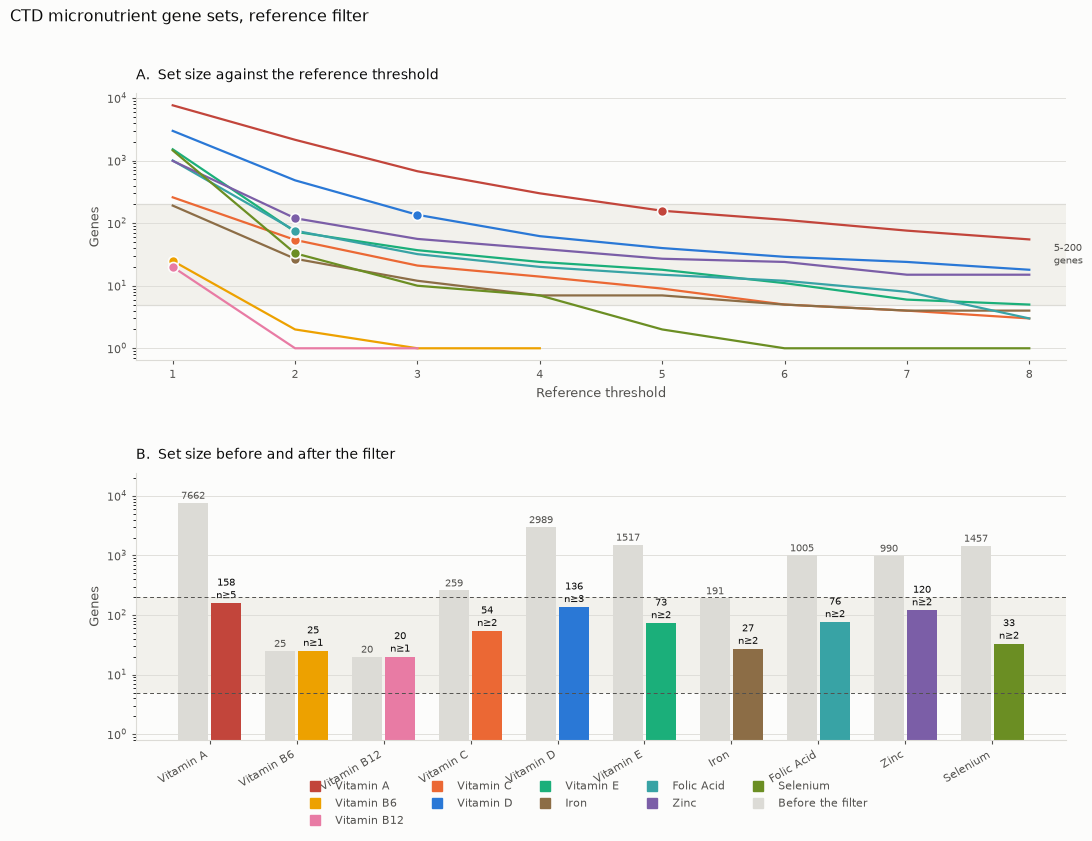

In [9]:
import ctd_threshold_figure as ctf

counts_by_set = {name: genes_all.loc[genes_all["Micronutrient"] == name,
                                     "NumReferences"].tolist()
                 for name in ORDER}
chosen = {row["Micronutrient"]: row["RefThreshold"] for row in rows}

figure = ctf.make_figure(
    counts_by_set,
    chosen,
    output_path=RESULTS / "ctd_micronutrients_threshold.png",
    order=ORDER,
    min_size=MIN_SET_SIZE,
    max_size=MAX_SET_SIZE,
)
plt.show()

Written to results/ctd/ctd_micronutrients_filtered.png


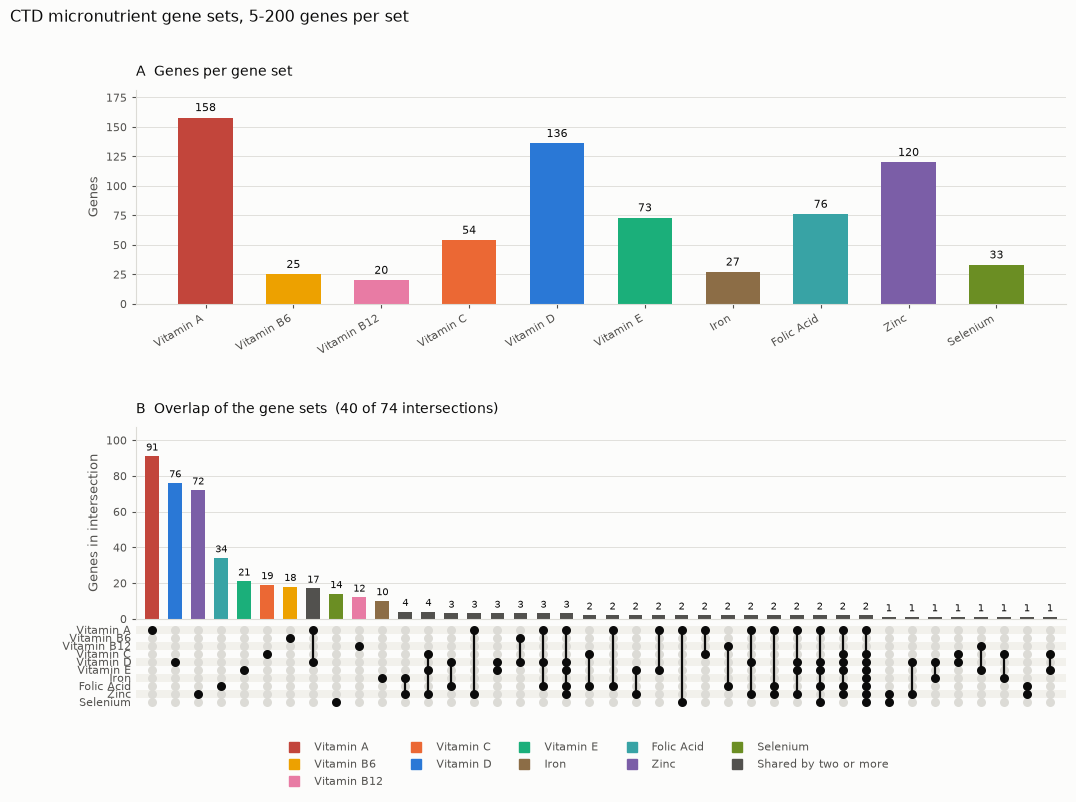

In [10]:
figure = csf.make_figure(
    sets_filtered,
    output_path=RESULTS / "ctd_micronutrients_filtered.png",
    subtitle=f", {MIN_SET_SIZE}-{MAX_SET_SIZE} genes per set",
    order=ORDER,
)
plt.show()

### Write the tables

In [11]:
cms.write_workbook(RESULTS / "ctd_micronutrient_sets.xlsx", {
    "Overview": pd.DataFrame(rows),
    "Genes_all": genes_all,
    "Genes_filtered": genes_filtered,
    "Interactions": direct,
})

Written to results/ctd/ctd_micronutrient_sets.xlsx
